# Validación de modelos

Para saber cómo se comportará un modelo con datos nuevos hay que evaluarlo con datos que no usó para aprender. La validación organiza esa evaluación: separa los datos, decide cómo se eligen los hiperparámetros y cómo se estima el error de generalización sin engañarse {cite}`james2021,kuhn2013`.

## Entrenamiento, validación y prueba

El esquema más simple divide los datos en un conjunto de entrenamiento, con el que se ajusta el modelo, y uno de prueba, con el que se mide su desempeño. Cuando además hay que elegir hiperparámetros (la profundidad de un árbol, el número de vecinos, la penalización), se necesita un tercer conjunto de validación, o una validación cruzada dentro del entrenamiento, porque si se eligen mirando el conjunto de prueba, este deja de ser independiente y el error reportado es optimista. El conjunto de prueba se usa una sola vez, al final.

## Validación cruzada

Una sola división depende del azar: con pocos datos, otra partición daría un resultado distinto. La validación cruzada de $k$ particiones (k-fold) divide los datos en $k$ partes, entrena $k$ veces dejando cada vez una parte fuera para evaluar y promedia los $k$ resultados. Valores de $k$ entre 5 y 10 son un buen compromiso entre sesgo y varianza de la estimación. La validación dejando uno fuera (leave-one-out) es el caso extremo $k = n$. Para clasificación con clases desbalanceadas se usa la versión estratificada, que conserva la proporción de clases en cada partición. Para series de tiempo, las particiones deben respetar el orden temporal: se entrena con el pasado y se evalúa con el futuro.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from scipy import ndimage
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(1)

def inventario_espacial(n=3000, semilla=1):
    """Inventario sintético con coordenadas: la susceptibilidad tiene una componente espacial suave no medida."""
    r = np.random.default_rng(semilla)
    xy = r.uniform(0, 20, (n, 2))                         # km
    campo = ndimage.gaussian_filter(r.normal(0, 1, (200, 200)), 18); campo /= campo.std()
    latente = campo[(xy[:, 1] * 10).astype(int).clip(0, 199), (xy[:, 0] * 10).astype(int).clip(0, 199)]
    pend = r.gamma(4, 6, n); dist = r.exponential(250, n)
    eta = -3 + 0.06 * pend - 0.003 * dist + 2.8 * latente
    y = (r.random(n) < 1 / (1 + np.exp(-eta))).astype(int)
    X = np.column_stack([pend, dist, xy])                 # las coordenadas se incluyen como predictores
    return X, y, xy

X, y, xy = inventario_espacial()
modelo = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1)
divs = []
for s in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=s, stratify=y)
    divs.append(modelo.fit(X_tr, y_tr).score(X_te, y_te))
cv = cross_val_score(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0))
print(f'20 divisiones aleatorias 70/30: exactitud entre {min(divs):.3f} y {max(divs):.3f}')
print(f'Validación cruzada estratificada de 5 particiones: {cv.mean():.3f} ± {cv.std():.3f}')

20 divisiones aleatorias 70/30: exactitud entre 0.906 y 0.930
Validación cruzada estratificada de 5 particiones: 0.922 ± 0.009


## Validación espacial

En geociencias hay una trampa frecuente. Los datos espaciales están autocorrelacionados: dos celdas vecinas se parecen más que dos lejanas. Si las particiones se hacen al azar, cada punto de prueba tiene vecinos casi idénticos en el entrenamiento, y el modelo, sobre todo si es flexible o si usa las coordenadas como predictores, acierta por proximidad y no porque haya aprendido la relación con las variables. El error estimado así es optimista para predecir en zonas nuevas, que es justamente para lo que suele usarse un mapa de susceptibilidad {cite}`roberts2017`.

La validación cruzada espacial agrupa los datos en bloques espaciales y deja bloques completos fuera en cada partición, de modo que los puntos de prueba quedan lejos de los de entrenamiento. La celda siguiente la compara con la validación aleatoria.

aleatoria (k=5)              bosque aleatorio con coordenadas       AUC 0.876
aleatoria (k=5)              regresión logística sin coordenadas    AUC 0.616


espacial por bloques (k=4)   bosque aleatorio con coordenadas       AUC 0.688
espacial por bloques (k=4)   regresión logística sin coordenadas    AUC 0.617


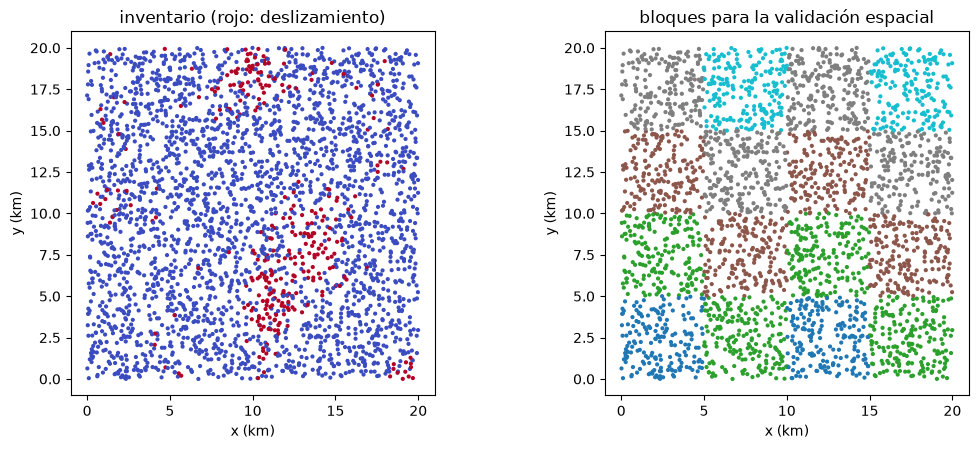

In [2]:
bloque = (xy[:, 0] // 5).astype(int) * 4 + (xy[:, 1] // 5).astype(int)     # 16 bloques de 5 x 5 km
res = {}
for nom, cvobj, grupos in [('aleatoria (k=5)', KFold(5, shuffle=True, random_state=0), None),
                           ('espacial por bloques (k=4)', GroupKFold(4), bloque)]:
    for mnom, m in [('bosque aleatorio con coordenadas', modelo),
                    ('regresión logística sin coordenadas', None)]:
        Xm = X if m is not None else X[:, :2]
        mm = m if m is not None else LogisticRegression(max_iter=1000)
        s = cross_val_score(mm, Xm, y, cv=cvobj, groups=grupos, scoring='roc_auc')
        res[(nom, mnom)] = s.mean()
        print(f'{nom:28s} {mnom:38s} AUC {s.mean():.3f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].scatter(xy[:, 0], xy[:, 1], c=y, cmap='coolwarm', s=4); ax[0].set_title('inventario (rojo: deslizamiento)')
ax[1].scatter(xy[:, 0], xy[:, 1], c=bloque % 4 + (bloque // 4) % 2, cmap='tab10', s=4); ax[1].set_title('bloques para la validación espacial')
for a in ax: a.set_aspect('equal'); a.set_xlabel('x (km)'); a.set_ylabel('y (km)')
plt.tight_layout(); plt.show()

Con validación aleatoria, el bosque aleatorio que usa las coordenadas parece mucho mejor que la regresión logística, porque aprende de memoria la componente espacial no medida a partir de los vecinos; con validación espacial su AUC cae de forma marcada, porque fuera de los bloques de entrenamiento las coordenadas no le sirven. La validación espacial da la estimación honesta del desempeño en zonas no muestreadas. La regla práctica es que la validación debe imitar el uso que se le dará al modelo.

## Selección de hiperparámetros con validación cruzada anidada

Cuando se eligen hiperparámetros con validación cruzada y se reporta el mejor puntaje de esa misma búsqueda, la estimación vuelve a ser optimista, porque se eligió el máximo de varios valores ruidosos. La solución es la validación cruzada anidada: un ciclo interno elige los hiperparámetros y un ciclo externo evalúa el procedimiento completo. Los detalles de la búsqueda se tratan en el capítulo {doc}`09_Optimizacion`.

In [3]:
from sklearn.model_selection import GridSearchCV
busq = GridSearchCV(RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
                    {'max_depth': [2, 4, 8, None], 'min_samples_leaf': [1, 5, 20]}, cv=GroupKFold(4))
busq.fit(X[:, :2], y, groups=bloque)
print(f'Mejores hiperparámetros: {busq.best_params_}; puntaje de la búsqueda {busq.best_score_:.3f}')

externo = []
for tr, te in GroupKFold(4).split(X, y, bloque):
    b = GridSearchCV(RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1),
                     {'max_depth': [2, 4, 8, None], 'min_samples_leaf': [1, 5, 20]}, cv=GroupKFold(3))
    b.fit(X[tr, :2], y[tr], groups=bloque[tr])
    externo.append(b.score(X[te, :2], y[te]))
print(f'Validación anidada (espacial): {np.mean(externo):.3f} ± {np.std(externo):.3f}')

Mejores hiperparámetros: {'max_depth': 2, 'min_samples_leaf': 1}; puntaje de la búsqueda 0.894


Validación anidada (espacial): 0.894 ± 0.061


## Para profundizar

El capítulo 5 de {cite}`james2021` trata la validación cruzada y el bootstrap, y el capítulo 4 de {cite}`kuhn2013` discute el diseño de la validación. {cite:t}`roberts2017` es la referencia básica sobre validación con datos espaciales, temporales o jerárquicos. El notebook 08 del curso aplica distintos esquemas de validación.